# 5. Post-process & Visualize Aggregation Results
Compares scenarios from `results/aggregated_load_nodes_wide_resstock_plus_ami_fallback_RES_*` (15-min, kW per transformer node) from **energy** (annual, monthly) and **demand** (annual, seasonal, monthly peaks) perspectives, at system and node level.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

RESULTS = Path("../results")
FIG_DIR = RESULTS / "figures_postprocess"
FIG_DIR.mkdir(exist_ok=True)
PREFIX = "aggregated_load_nodes_wide_resstock_plus_ami_fallback_RES_"

SCENARIOS = {  # label -> file tag
    "Baseline": "baseline_rebuilt_ami-zero",
    "Upgrade 04": "up04_rebuilt_ami-zero",
    "Upgrade 04 + DF (2F)": "up04_df_2F_ami-zero",
}
BASE = "Baseline"
UP, DF = "Upgrade 04", "Upgrade 04 + DF (2F)"
# Pairwise comparisons: (scenario, reference)
COMPARISONS = [(UP, BASE), (DF, BASE), (DF, UP)]
cmp_label = lambda a, b: f"{a} vs {b}"
PEAK_DAY_SCEN = UP  # scenario whose winter/summer peak days are used for profile comparison
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}
SEASON_ORDER = ["Winter", "Spring", "Summer", "Fall"]

# DF peak window: ResStock 2025R1 ResStockArgumentsPostHPXML, seasonal_shedding_peak_hours.json (NY).
# Measure seasons and [start, end) hours in standard time, applied every day (see "DF peak window" section).
DF_SEASON = {m: "summer" if m in (6, 7, 8, 9) else "winter" if m in (12, 1, 2, 3) else "intermediate"
             for m in range(1, 13)}
DF_WINDOW = {"winter": (17, 21), "intermediate": (17, 21), "summer": (18, 22)}
WINDOW_LAG = pd.Timedelta("15min")  # observed one-timestep lag of the load response in the 15-min labels (0 = nominal)


def in_window(idx):
    """Boolean mask of interval-end timestamps whose (lagged) interval falls in the DF peak window."""
    dt = idx.to_series().diff().mode()[0]
    start = idx - dt - WINDOW_LAG
    h = np.asarray(start.hour + start.minute / 60)
    sea = pd.Series((idx - dt).month).map(DF_SEASON)
    lo = sea.map(lambda s: DF_WINDOW[s][0]).to_numpy()
    hi = sea.map(lambda s: DF_WINDOW[s][1]).to_numpy()
    return (h >= lo) & (h < hi)


In [2]:
def load(tag):
    pq, csv = RESULTS / f"{PREFIX}{tag}.parquet", RESULTS / f"{PREFIX}{tag}.csv"
    df = pd.read_parquet(pq) if pq.exists() else pd.read_csv(csv)
    if "time" in df.columns:
        df = df.set_index("time")
    df.index = pd.to_datetime(df.index)
    return df.sort_index().astype(float)

data = {lab: load(tag) for lab, tag in SCENARIOS.items()}
dt_h = pd.Series(data[BASE].index).diff().mode()[0] / pd.Timedelta("1h")
print(f"Timestep: {dt_h} h")
# Source values are kWh per interval -> convert to average kW
data = {k: v / dt_h for k, v in data.items()}
for lab, df in data.items():
    print(f"{lab:25s} shape={df.shape}  {df.index.min()} -> {df.index.max()}  NaNs={int(df.isna().sum().sum())}")

# Common nodes across scenarios
nodes = sorted(set.intersection(*[set(d.columns) for d in data.values()]))
data = {k: v[nodes] for k, v in data.items()}
print(f"Common nodes: {len(nodes)}")

Timestep: 0.25 h
Baseline                  shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
Upgrade 04                shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
Upgrade 04 + DF (2F)      shape=(35040, 146)  2024-01-01 00:00:00 -> 2024-12-31 23:45:00  NaNs=0
Common nodes: 146


## System-level time series

In [13]:
sys_kw = pd.DataFrame({lab: df.sum(axis=1) for lab, df in data.items()})
sys_kw["month"] = sys_kw.index.month
sys_kw["season"] = sys_kw.index.month.map(SEASONS)
sys_kw["df_season"] = (sys_kw.index - pd.Timedelta(hours=dt_h)).month.map(DF_SEASON)
sys_kw["in_window"] = in_window(sys_kw.index)
scen = list(SCENARIOS)
print(f"DF window: {sys_kw['in_window'].sum()} intervals = {sys_kw['in_window'].sum() * dt_h:,.0f} h/yr")

# Sanity check vs aggregation report (kWh)
rep = RESULTS / "resstock_aggregation_report_baseline_rebuilt.csv"
if rep.exists():
    r = pd.read_csv(rep)
    print(f"Report kWh_total: {r['kWh_total'].sum():,.0f}  |  computed baseline: {(sys_kw[BASE]*dt_h).sum():,.0f}")


DF window: 5840 intervals = 1,460 h/yr
Report kWh_total: 4,013,436  |  computed baseline: 4,013,436


## Summary statistics table

In [14]:
def summary(s):
    e = s.sum() * dt_h
    pk = s.max()
    return pd.Series({
        "Annual energy (MWh)": e / 1000,
        "Peak demand (kW)": pk,
        "Peak time": s.idxmax(),
        "Average load (kW)": s.mean(),
        "Minimum load (kW)": s.min(),
        "Load factor (%)": 100 * s.mean() / pk,
        "P95 load (kW)": s.quantile(0.95),
        "P99 load (kW)": s.quantile(0.99),
        "Hours > 90% of peak": (s > 0.9 * pk).sum() * dt_h,
    })

summ = pd.DataFrame({c: summary(sys_kw[c]) for c in scen}).T
summ.to_csv(FIG_DIR / "system_summary.csv")
display(summ)

# Pairwise changes
metrics = ["Annual energy (MWh)", "Peak demand (kW)", "Average load (kW)", "Load factor (%)", "P95 load (kW)", "P99 load (kW)"]
pair_tbl = {}
for a, b in COMPARISONS:
    row = {f"Δ {m}": float(summ.loc[a, m]) - float(summ.loc[b, m]) for m in metrics}
    for m in metrics[:2]:
        row[f"Δ% {m}"] = 100 * (float(summ.loc[a, m]) / float(summ.loc[b, m]) - 1)
    pair_tbl[cmp_label(a, b)] = row
pair_tbl = pd.DataFrame(pair_tbl).T
pair_tbl.to_csv(FIG_DIR / "system_pairwise_changes.csv")
pair_tbl

,Annual energy (MWh),Peak demand (kW),Peak time,Average load (kW),Minimum load (kW),Load factor (%),P95 load (kW),P99 load (kW),Hours > 90% of peak
Baseline,"4,013.44","1,115.97",2024-12-21 18:45:00,458.15,64.18,41.05,737.05,893.10,15.25
Upgrade 04,"5,678.66","1,743.42",2024-01-14 12:30:00,648.25,64.18,37.18,"1,130.62","1,368.78",10.75
Upgrade 04 + DF (2F),"5,629.38","1,743.78",2024-01-14 12:30:00,642.62,64.18,36.85,"1,124.23","1,363.31",8.50


,Δ Annual energy (MWh),Δ Peak demand (kW),Δ Average load (kW),Δ Load factor (%),Δ P95 load (kW),Δ P99 load (kW),Δ% Annual energy (MWh),Δ% Peak demand (kW)
Upgrade 04 vs Baseline,"1,665.22",627.45,190.09,-3.87,393.57,475.68,41.49,56.22
Upgrade 04 + DF (2F) vs Baseline,"1,615.94",627.81,184.47,-4.20,387.18,470.21,40.26,56.26
Upgrade 04 + DF (2F) vs Upgrade 04,-49.28,0.36,-5.63,-0.33,-6.38,-5.47,-0.87,0.02


## Energy: annual and monthly

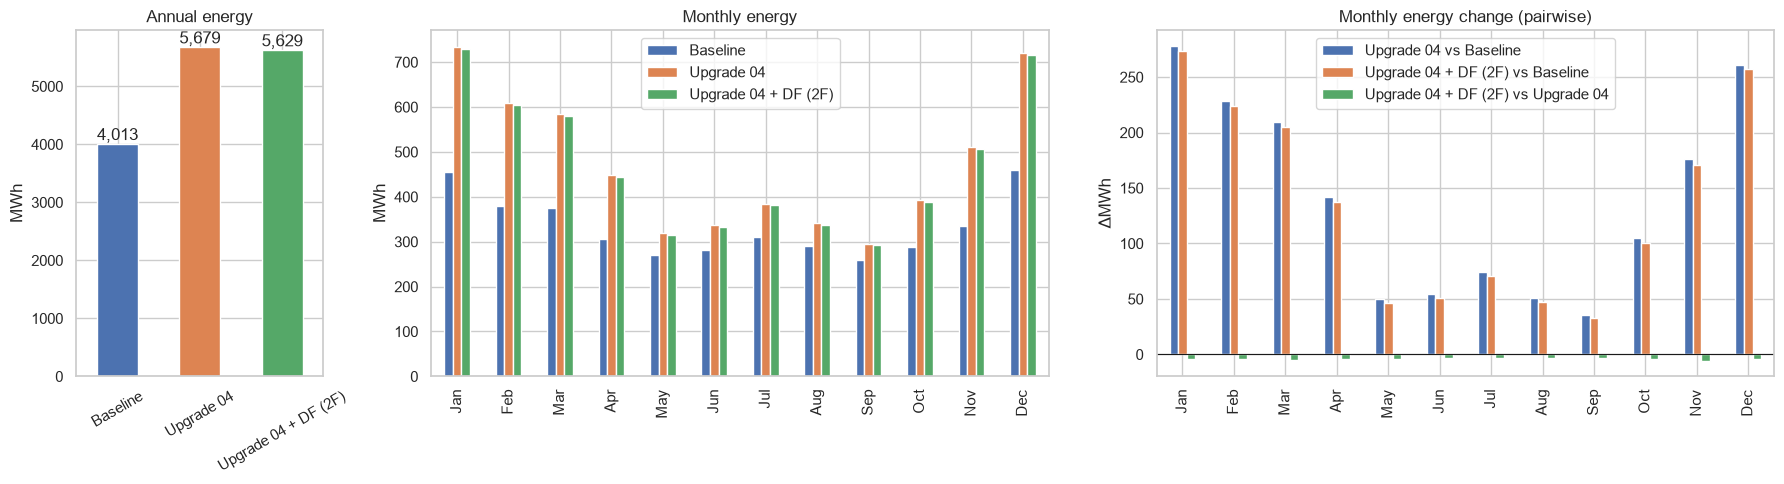

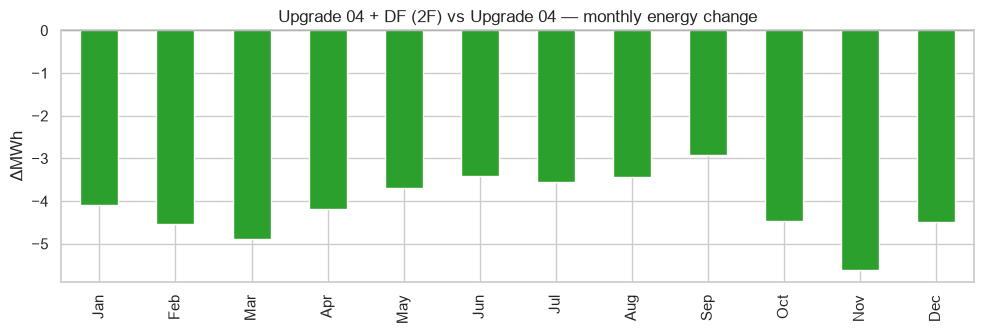

,Baseline,Upgrade 04,Upgrade 04 + DF (2F),Δ% Upgrade 04 vs Baseline,Δ% Upgrade 04 + DF (2F) vs Baseline,Δ% Upgrade 04 + DF (2F) vs Upgrade 04
Jan,456.02,733.86,729.76,60.93,60.03,-0.56
Feb,379.32,608.14,603.60,60.32,59.13,-0.75
Mar,375.78,585.51,580.62,55.81,54.51,-0.83
Apr,306.00,447.63,443.44,46.28,44.91,-0.94
May,269.34,319.44,315.75,18.60,17.23,-1.16
Jun,282.31,336.87,333.47,19.33,18.12,-1.01
Jul,310.69,384.61,381.06,23.79,22.65,-0.92
Aug,290.30,341.38,337.94,17.60,16.41,-1.01
Sep,260.31,295.72,292.80,13.60,12.48,-0.99
Oct,287.88,392.75,388.28,36.43,34.88,-1.14


In [15]:
monthly_mwh = sys_kw.groupby("month")[scen].sum() * dt_h / 1000
monthly_mwh.index = pd.to_datetime(monthly_mwh.index, format="%m").strftime("%b")
monthly_delta = pd.DataFrame({cmp_label(a, b): monthly_mwh[a] - monthly_mwh[b] for a, b in COMPARISONS})

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 2.5, 2.5]})
summ["Annual energy (MWh)"].astype(float).plot.bar(ax=axes[0], color=sns.color_palette()[:len(scen)])
axes[0].set(title="Annual energy", ylabel="MWh"); axes[0].tick_params(axis="x", rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
monthly_mwh.plot.bar(ax=axes[1]); axes[1].set(title="Monthly energy", ylabel="MWh", xlabel="")
monthly_delta.plot.bar(ax=axes[2]); axes[2].axhline(0, color="k", lw=0.8)
axes[2].set(title="Monthly energy change (pairwise)", ylabel="ΔMWh", xlabel="")
plt.tight_layout(); fig.savefig(FIG_DIR / "energy_annual_monthly.png", dpi=150); plt.show()

# Zoom: DF vs Up04 (small relative to the upgrade effect)
ax = monthly_delta[cmp_label(DF, UP)].plot.bar(figsize=(10, 3.5), color="tab:green")
ax.axhline(0, color="k", lw=0.8); ax.set(title=cmp_label(DF, UP) + " — monthly energy change", ylabel="ΔMWh", xlabel="")
plt.tight_layout(); plt.savefig(FIG_DIR / "energy_monthly_df_vs_up04.png", dpi=150); plt.show()

monthly_tbl = pd.concat([monthly_mwh, monthly_mwh.sum().to_frame("Annual").T])
for a, b in COMPARISONS:
    monthly_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (monthly_tbl[a] / monthly_tbl[b] - 1)
monthly_tbl.to_csv(FIG_DIR / "monthly_energy_mwh.csv")
monthly_tbl

## Demand: annual, seasonal, monthly peaks

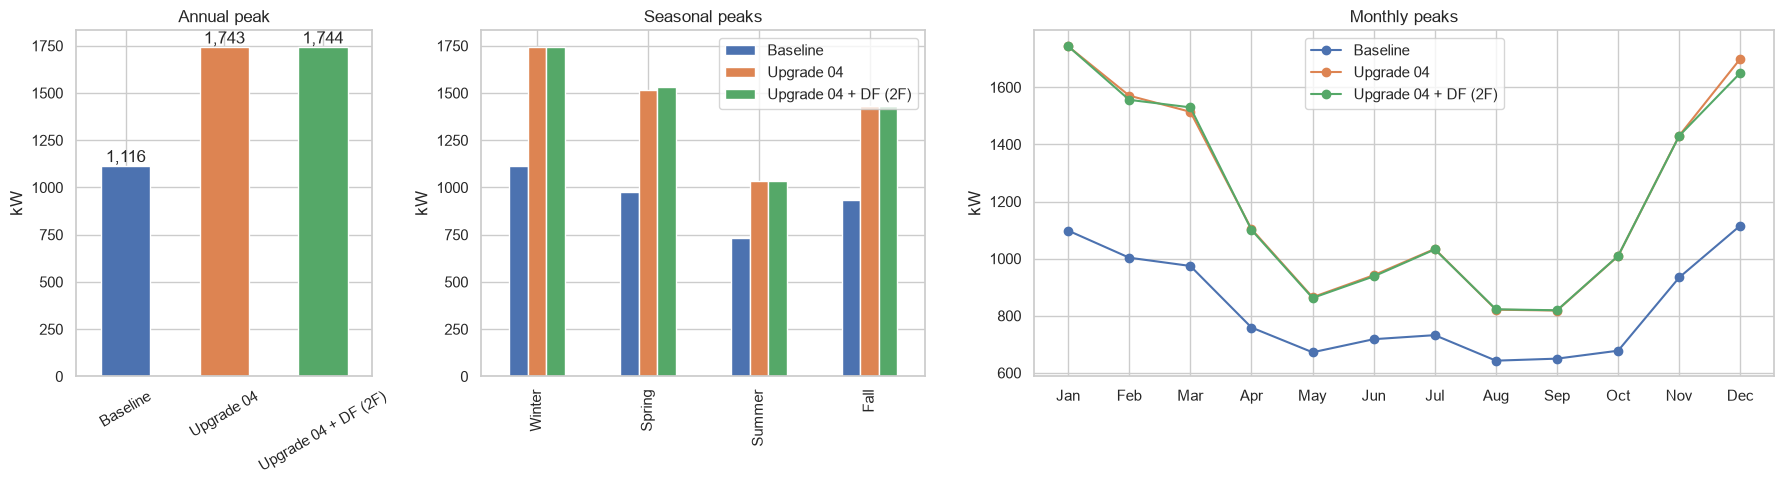

Peak (kW)                                                            \
        Baseline Upgrade 04 Upgrade 04 + DF (2F) Δ% Upgrade 04 vs Baseline   
season                                                                       
Winter  1,115.97   1,743.42             1,743.78                     56.22   
Spring    974.34   1,514.05             1,529.58                     55.39   
Summer    732.08   1,034.00             1,032.31                     41.24   
Fall      934.19   1,430.87             1,430.13                     53.17   

                                            \
       Δ% Upgrade 04 + DF (2F) vs Baseline   
season                                       
Winter                               56.26   
Spring                               56.99   
Summer                               41.01   
Fall                                 53.09   

                                                       Peak time  \
       Δ% Upgrade 04 + DF (2F) vs Upgrade 04            Baseline   
season                                                             
Winter                                  0.02 2024-12-21 18:45:00   
Spring                                  1.03 2024-03-10 22:15:00   
Summer                                 -0.16 2024-07-15 17:15:00   
Fall                                   -0.05 2024-11-30 13:15:00   

                                                 
                Upgrade 04 Upgrade 04 + DF (2F)  
season                                           
Winter 2024-01-14 12:30:00  2024-01-14 12:30:00  
Spring 2024-03-10 22:15:00  2024-03-10 22:15:00  
Summer 2024-07-15 17:15:00  2024-07-15 17:15:00  
Fall   2024-11-30 13:15:00  2024-11-30 13:15:00

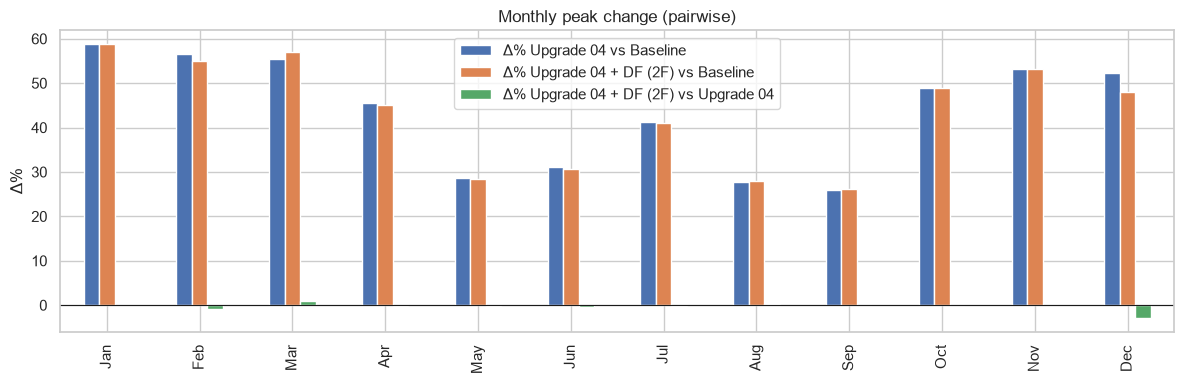

,Baseline,Upgrade 04,Upgrade 04 + DF (2F),Δ% Upgrade 04 vs Baseline,Δ% Upgrade 04 + DF (2F) vs Baseline,Δ% Upgrade 04 + DF (2F) vs Upgrade 04
month,,,,,,
Jan,"1,098.22","1,743.42","1,743.78",58.75,58.78,0.02
Feb,"1,003.23","1,570.59","1,555.97",56.55,55.10,-0.93
Mar,974.34,"1,514.05","1,529.58",55.39,56.99,1.03
Apr,758.87,"1,103.71","1,100.58",45.44,45.03,-0.28
May,672.04,864.92,862.30,28.70,28.31,-0.30
Jun,717.93,941.91,937.71,31.20,30.61,-0.45
Jul,732.08,"1,034.00","1,032.31",41.24,41.01,-0.16
Aug,642.75,821.22,822.65,27.77,27.99,0.17
Sep,649.83,818.25,819.16,25.92,26.06,0.11


In [16]:
seasonal_pk = sys_kw.groupby("season")[scen].max().reindex(SEASON_ORDER)
seasonal_pk_time = sys_kw.groupby("season")[scen].idxmax().reindex(SEASON_ORDER)
monthly_pk = sys_kw.groupby("month")[scen].max()
monthly_pk.index = pd.to_datetime(monthly_pk.index, format="%m").strftime("%b")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.5, 2.5]})
summ["Peak demand (kW)"].astype(float).plot.bar(ax=axes[0], color=sns.color_palette()[:len(scen)])
axes[0].set(title="Annual peak", ylabel="kW"); axes[0].tick_params(axis="x", rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
seasonal_pk.plot.bar(ax=axes[1]); axes[1].set(title="Seasonal peaks", ylabel="kW", xlabel="")
monthly_pk.plot(ax=axes[2], marker="o"); axes[2].set(title="Monthly peaks", ylabel="kW", xlabel="")
axes[2].set_xticks(range(12)); axes[2].set_xticklabels(monthly_pk.index)
plt.tight_layout(); fig.savefig(FIG_DIR / "demand_peaks.png", dpi=150); plt.show()

sea_tbl = seasonal_pk.copy()
for a, b in COMPARISONS:
    sea_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (seasonal_pk[a] / seasonal_pk[b] - 1)
sea_tbl.to_csv(FIG_DIR / "seasonal_peaks_kw.csv")
display(pd.concat({"Peak (kW)": sea_tbl, "Peak time": seasonal_pk_time}, axis=1))

pk_tbl = monthly_pk.copy()
for a, b in COMPARISONS:
    pk_tbl[f"Δ% {cmp_label(a, b)}"] = 100 * (monthly_pk[a] / monthly_pk[b] - 1)

fig, ax = plt.subplots(figsize=(12, 4))
pk_tbl[[f"Δ% {cmp_label(a, b)}" for a, b in COMPARISONS]].plot.bar(ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(title="Monthly peak change (pairwise)", ylabel="Δ%", xlabel="")
plt.tight_layout(); fig.savefig(FIG_DIR / "monthly_peak_pairwise.png", dpi=150); plt.show()

pk_tbl.to_csv(FIG_DIR / "monthly_peaks_kw.csv")
pk_tbl

## DF peak window: definition and justification
The DF scenario uses the ResStock 2025R1 measure `ResStockArgumentsPostHPXML`, run with `hvac_flex_peak_offset = 2°F`, `pre_peak_duration_hours = 0` (shed only) and `random_shift = 0`. It sets the thermostat back during a daily peak window. With no pre-peak period, the measure (`resources/common/schedule_modifier.rb::_get_peak_hour`) takes the window from `seasonal_shedding_peak_hours.json`. That file lists the Cambium 2050 MidCase net-load peak hours for each state and season (Gagnon et al., 2024). The window applies every day.

| Measure season | Months | NY window (standard time) |
|---|---|---|
| Winter | Dec, Jan, Feb, Mar | 17:00–21:00 |
| Intermediate | Apr, May, Oct, Nov | 17:00–21:00 |
| Summer | Jun–Sep | 18:00–22:00 |

**Evidence that this window was the one applied:**
- **Schedule:** in the DF `in.schedules.csv` (identical across the buildings checked), `peak_period` is 1 over these hours. During DST (Mar 11 to Nov 4) the file shifts the hours by +1 h, and EnergyPlus applies DST when it looks up schedule values. As a result, the window stays at the same clock hours in standard time, and the simulation output is in standard time.
- **Load response:** the DF − Up04 system delta is negative over exactly 16 intervals per day (4 h). It is followed by a rebound spike in the next interval. On the 15-min interval-end labels, the response appears one timestep later than nominal: labels 17:30–21:15 in winter and intermediate months, and 18:30–22:15 in summer. `WINDOW_LAG` (15 min) captures this lag in the mask. Set it to 0 to use the nominal window.

The **DF window** peak below is the maximum load within the window. The **All hours** peak (the earlier analysis) can occur outside the window. For example, the annual peak on Jan 14 at 12:30 falls outside the window, and DF is not designed to reduce such peaks.


bldg0000510 peak_period windows (schedule-file clock; +1 h during DST, Mar 11–Nov 4):


,window
2023-01-01,17:00–21:00
2023-03-11,18:00–22:00
2023-06-01,19:00–23:00
2023-10-01,18:00–22:00
2023-11-04,17:00–21:00


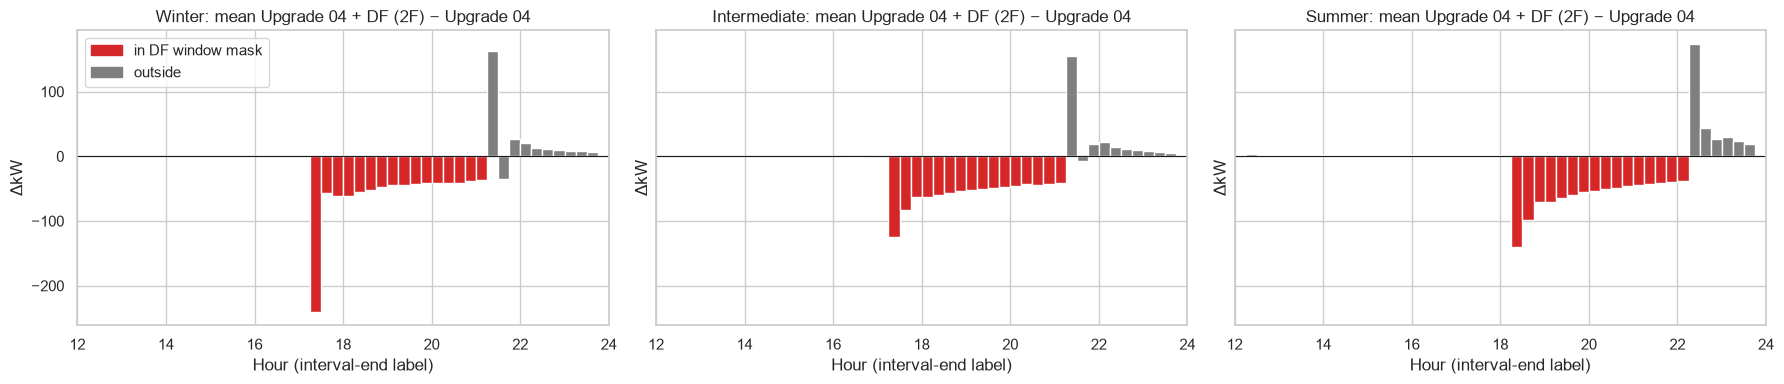

In [18]:
# Verify the window: (1) DF schedule peak_period flags, (2) mean DF − Up04 delta by time of day with the window mask shaded
from matplotlib.patches import Patch

sched = sorted(Path("../data/resstock_models_up04_df").glob("bldg*/run/in.schedules.csv"))
if sched:
    pp = pd.read_csv(sched[0], usecols=["peak_period"])["peak_period"]
    pp.index = pd.date_range("2023-01-01", periods=len(pp), freq="15min")  # interval start
    on = pp[pp > 0]
    w = on.groupby(on.index.normalize()).agg(lambda x: f"{x.index.min():%H:%M}–{x.index.max() + pd.Timedelta('15min'):%H:%M}")
    print(f"{sched[0].parts[-3]} peak_period windows (schedule-file clock; +1 h during DST, Mar 11–Nov 4):")
    display(w[w != w.shift()].rename("window").to_frame())

delta = sys_kw[DF] - sys_kw[UP]
tod = sys_kw.index.hour + sys_kw.index.minute / 60
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for ax, s in zip(axes, ["winter", "intermediate", "summer"]):
    m = (sys_kw["df_season"] == s).to_numpy()
    prof = delta[m].groupby(tod[m]).mean()
    win = sys_kw.loc[m, "in_window"].groupby(tod[m]).mean().reindex(prof.index) > 0.5
    # bar spans the interval ending at its label
    ax.bar(prof.index, prof.values, width=-dt_h, align="edge", color=np.where(win, "tab:red", "tab:gray"))
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"{s.title()}: mean {DF} − {UP}", xlabel="Hour (interval-end label)", ylabel="ΔkW", xlim=(12, 24))
axes[0].legend(handles=[Patch(color="tab:red", label="in DF window mask"), Patch(color="tab:gray", label="outside")])
plt.tight_layout(); fig.savefig(FIG_DIR / "df_window_verification.png", dpi=150); plt.show()

## Peak demand: DF window vs all hours

All hours                                                            \
        Baseline Upgrade 04 Upgrade 04 + DF (2F) Δ% Upgrade 04 vs Baseline   
Annual  1,115.97   1,743.42             1,743.78                     56.22   
Winter  1,115.97   1,743.42             1,743.78                     56.22   
Spring    974.34   1,514.05             1,529.58                     55.39   
Summer    732.08   1,034.00             1,032.31                     41.24   
Fall      934.19   1,430.87             1,430.13                     53.17   
Jan     1,098.22   1,743.42             1,743.78                     58.75   
Feb     1,003.23   1,570.59             1,555.97                     56.55   
Mar       974.34   1,514.05             1,529.58                     55.39   
Apr       758.87   1,103.71             1,100.58                     45.44   
May       672.04     864.92               862.30                     28.70   
Jun       717.93     941.91               937.71                     31.20   
Jul       732.08   1,034.00             1,032.31                     41.24   
Aug       642.75     821.22               822.65                     27.77   
Sep       649.83     818.25               819.16                     25.92   
Oct       677.69   1,009.04             1,009.59                     48.89   
Nov       934.19   1,430.87             1,430.13                     53.17   
Dec     1,115.97   1,700.14             1,650.53                     52.35   

                                            \
       Δ% Upgrade 04 + DF (2F) vs Baseline   
Annual                               56.26   
Winter                               56.26   
Spring                               56.99   
Summer                               41.01   
Fall                                 53.09   
Jan                                  58.78   
Feb                                  55.10   
Mar                                  56.99   
Apr                                  45.03   
May                                  28.31   
Jun                                  30.61   
Jul                                  41.01   
Aug                                  27.99   
Sep                                  26.06   
Oct                                  48.97   
Nov                                  53.09   
Dec                                  47.90   

                                             DF window             \
       Δ% Upgrade 04 + DF (2F) vs Upgrade 04  Baseline Upgrade 04   
Annual                                  0.02  1,115.97   1,700.14   
Winter                                  0.02  1,115.97   1,700.14   
Spring                                  1.03    951.25   1,392.45   
Summer                                 -0.16    717.93     941.91   
Fall                                   -0.05    918.02   1,330.73   
Jan                                     0.02  1,098.22   1,633.04   
Feb                                    -0.93  1,003.23   1,570.59   
Mar                                     1.03    951.25   1,392.45   
Apr                                    -0.28    758.87   1,103.71   
May                                    -0.30    672.04     864.92   
Jun                                    -0.45    717.93     941.91   
Jul                                    -0.16    689.29     870.85   
Aug                                     0.17    641.46     814.60   
Sep                                     0.11    649.83     800.80   
Oct                                     0.05    600.61     851.90   
Nov                                    -0.05    918.02   1,330.73   
Dec                                    -2.92  1,115.97   1,700.14   

                                                       \
       Upgrade 04 + DF (2F) Δ% Upgrade 04 vs Baseline   
Annual             1,650.53                     52.35   
Winter             1,650.53                     52.35   
Spring             1,356.20                     46.38   
Summer               905.52                     31.2

Peak timestamps (interval-end):


All hours                                           \
                  Baseline          Upgrade 04 Upgrade 04 + DF (2F)   
Annual 2024-12-21 18:45:00 2024-01-14 12:30:00  2024-01-14 12:30:00   
Winter 2024-12-21 18:45:00 2024-01-14 12:30:00  2024-01-14 12:30:00   
Spring 2024-03-10 22:15:00 2024-03-10 22:15:00  2024-03-10 22:15:00   
Summer 2024-07-15 17:15:00 2024-07-15 17:15:00  2024-07-15 17:15:00   
Fall   2024-11-30 13:15:00 2024-11-30 13:15:00  2024-11-30 13:15:00   

                 DF window                                           
                  Baseline          Upgrade 04 Upgrade 04 + DF (2F)  
Annual 2024-12-21 18:45:00 2024-12-21 18:45:00  2024-12-21 18:45:00  
Winter 2024-12-21 18:45:00 2024-12-21 18:45:00  2024-12-21 18:45:00  
Spring 2024-03-20 19:45:00 2024-03-20 19:45:00  2024-03-20 19:45:00  
Summer 2024-06-18 18:45:00 2024-06-19 18:45:00  2024-06-19 19:00:00  
Fall   2024-11-30 20:00:00 2024-11-30 20:00:00  2024-11-30 20:00:00

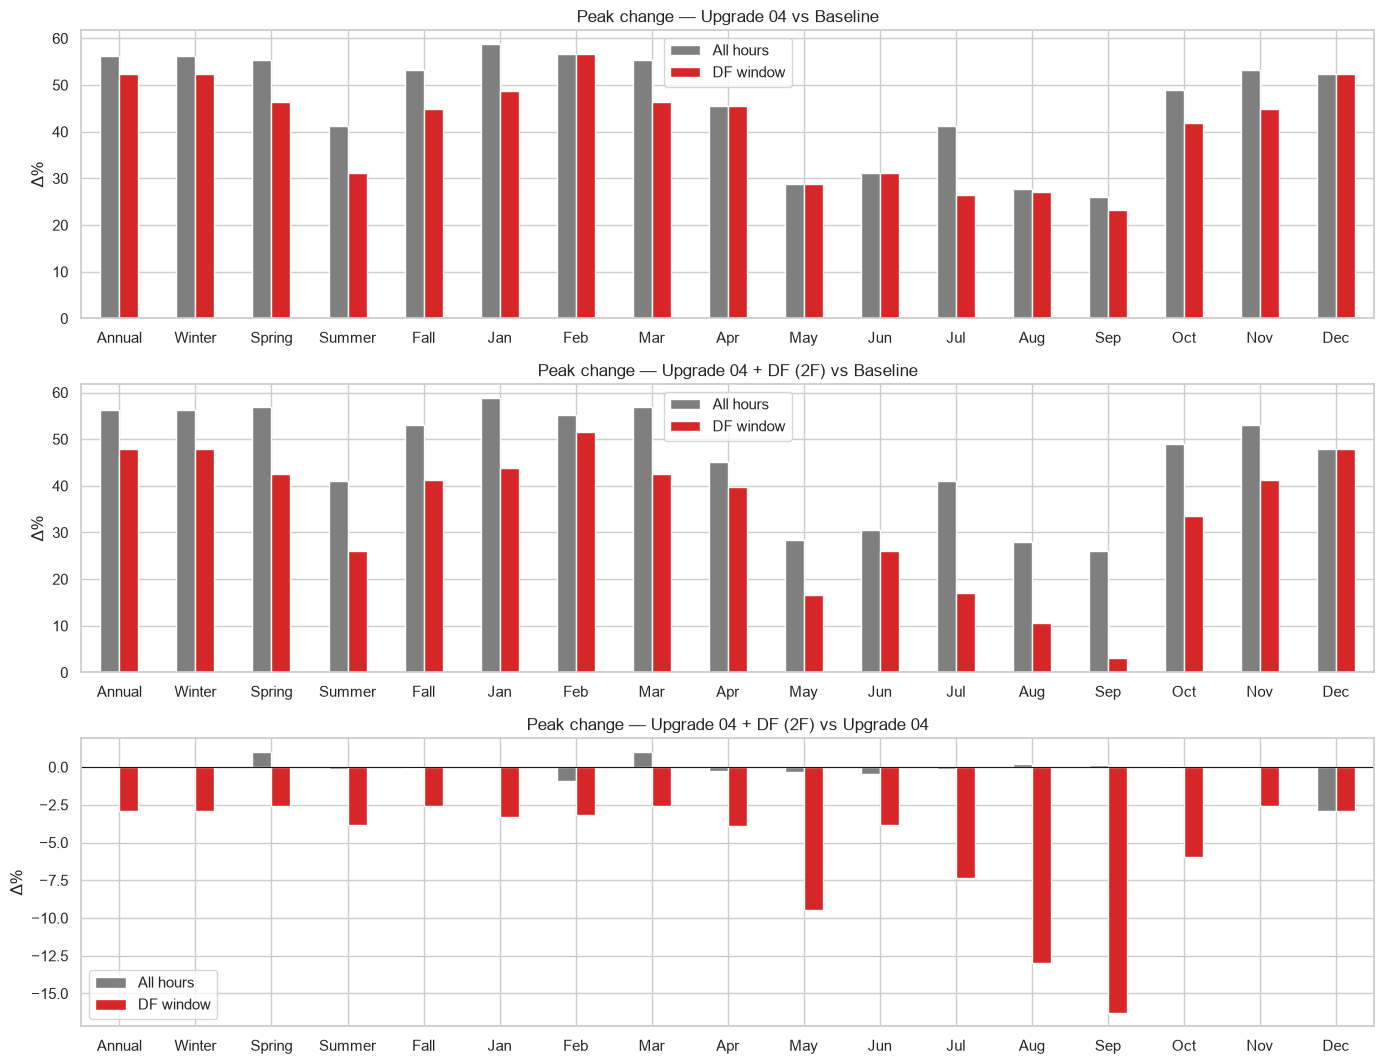

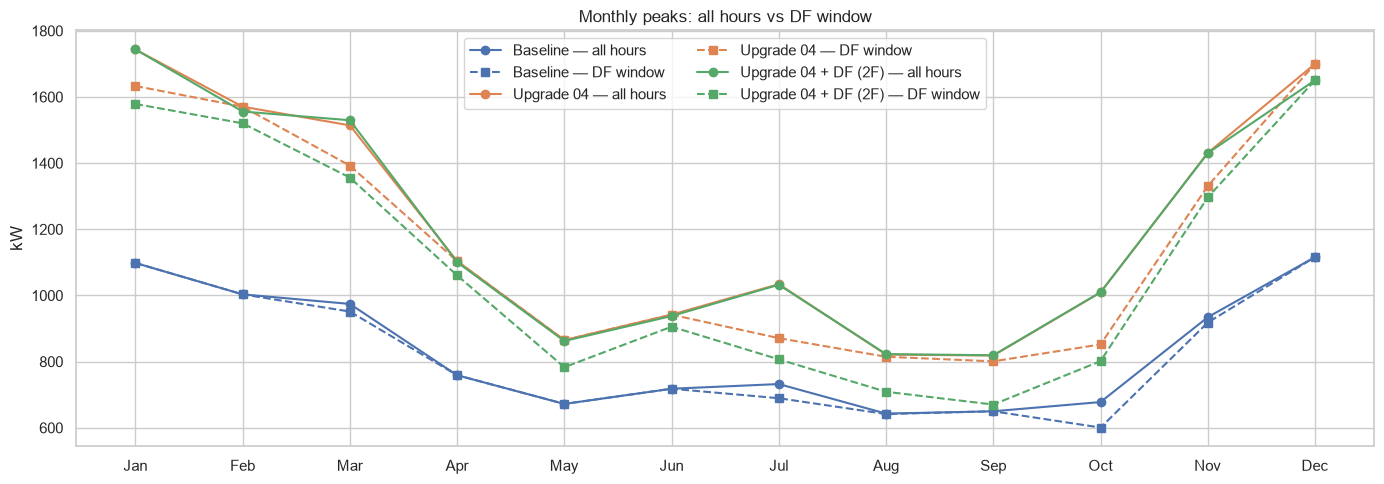

In [19]:
PERIODS = {"All hours": np.ones(len(sys_kw), bool), "DF window": sys_kw["in_window"].to_numpy()}


def peak_table(sub, fn="max"):
    ann = getattr(sub[scen], fn)().to_frame("Annual").T
    sea = getattr(sub.groupby("season")[scen], fn)().reindex(SEASON_ORDER)
    mon = getattr(sub.groupby("month")[scen], fn)()
    mon.index = pd.to_datetime(mon.index, format="%m").strftime("%b")
    return pd.concat([ann, sea, mon])


win_pk = pd.concat({p: peak_table(sys_kw[m]) for p, m in PERIODS.items()}, axis=1)
win_pk_time = pd.concat({p: peak_table(sys_kw[m], "idxmax") for p, m in PERIODS.items()}, axis=1)
for p in PERIODS:
    for a, b in COMPARISONS:
        win_pk[(p, f"Δ% {cmp_label(a, b)}")] = 100 * (win_pk[(p, a)] / win_pk[(p, b)] - 1)
win_pk = win_pk.sort_index(axis=1, level=0, sort_remaining=False)
win_pk.to_csv(FIG_DIR / "peaks_window_vs_all_kw.csv")
win_pk_time.to_csv(FIG_DIR / "peaks_window_vs_all_time.csv")
display(win_pk)
print("Peak timestamps (interval-end):")
display(win_pk_time.loc[["Annual"] + SEASON_ORDER])

# Pairwise peak Δ%: all hours vs DF window
fig, axes = plt.subplots(len(COMPARISONS), 1, figsize=(14, 3.6 * len(COMPARISONS)))
for ax, (a, b) in zip(axes, COMPARISONS):
    lab = f"Δ% {cmp_label(a, b)}"
    pd.DataFrame({p: win_pk[(p, lab)] for p in PERIODS}).plot.bar(ax=ax, color=["tab:gray", "tab:red"])
    ax.axhline(0, color="k", lw=0.8); ax.set(title=f"Peak change — {cmp_label(a, b)}", ylabel="Δ%", xlabel="")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); fig.savefig(FIG_DIR / "peak_change_window_vs_all.png", dpi=150); plt.show()

# Monthly peak magnitude: all hours (solid) vs DF window (dashed)
mon = win_pk.index[1 + len(SEASON_ORDER):]
fig, ax = plt.subplots(figsize=(14, 5))
for c, col in zip(scen, sns.color_palette()):
    ax.plot(mon, win_pk.loc[mon, ("All hours", c)], "-o", color=col, label=f"{c} — all hours")
    ax.plot(mon, win_pk.loc[mon, ("DF window", c)], "--s", color=col, label=f"{c} — DF window")
ax.set(title="Monthly peaks: all hours vs DF window", ylabel="kW"); ax.legend(ncol=2)
plt.tight_layout(); fig.savefig(FIG_DIR / "monthly_peaks_window_vs_all.png", dpi=150); plt.show()

In [20]:
# Shed & rebound by measure season: in-window energy, and peak in the 1 h right after the window
post = in_window(sys_kw.index - pd.Timedelta("1h")) & ~sys_kw["in_window"].to_numpy()
rows = []
for s in ["winter", "intermediate", "summer"]:
    ms = (sys_kw["df_season"] == s).to_numpy()
    w, q = sys_kw[ms & PERIODS["DF window"]], sys_kw[ms & post]
    n_days = ms.sum() * dt_h / 24
    for a, b in COMPARISONS:
        rows.append({
            "Measure season": s, "Comparison": cmp_label(a, b),
            "In-window energy Δ (MWh)": (w[a] - w[b]).sum() * dt_h / 1000,
            "In-window energy Δ%": 100 * (w[a].sum() / w[b].sum() - 1),
            "Avg in-window ΔkW": (w[a] - w[b]).mean(),
            "Post-window 1 h energy Δ (MWh)": (q[a] - q[b]).sum() * dt_h / 1000,
            "In-window peak Δ%": 100 * (w[a].max() / w[b].max() - 1),
            "Post-window 1 h peak Δ%": 100 * (q[a].max() / q[b].max() - 1),
            "Days": n_days,
        })
shed_tbl = pd.DataFrame(rows).set_index(["Measure season", "Comparison"])
shed_tbl.to_csv(FIG_DIR / "df_window_shed_rebound.csv")
shed_tbl

In-window energy Δ (MWh)  \
Measure season Comparison                                                     
winter         Upgrade 04 vs Baseline                                154.26   
               Upgrade 04 + DF (2F) vs Baseline                      125.70   
               Upgrade 04 + DF (2F) vs Upgrade 04                    -28.57   
intermediate   Upgrade 04 vs Baseline                                 65.39   
               Upgrade 04 + DF (2F) vs Baseline                       37.35   
               Upgrade 04 + DF (2F) vs Upgrade 04                    -28.04   
summer         Upgrade 04 vs Baseline                                 39.72   
               Upgrade 04 + DF (2F) vs Baseline                       10.22   
               Upgrade 04 + DF (2F) vs Upgrade 04                    -29.50   

                                                   In-window energy Δ%  \
Measure season Comparison                                                
winter         Upgrade 04 vs Baseline                            45.62   
               Upgrade 04 + DF (2F) vs Baseline                  37.17   
               Upgrade 04 + DF (2F) vs Upgrade 04                -5.80   
intermediate   Upgrade 04 vs Baseline                            25.89   
               Upgrade 04 + DF (2F) vs Baseline                  14.79   
               Upgrade 04 + DF (2F) vs Upgrade 04                -8.82   
summer         Upgrade 04 vs Baseline                            16.63   
               Upgrade 04 + DF (2F) vs Baseline                   4.28   
               Upgrade 04 + DF (2F) vs Upgrade 04               -10.59   

                                                   Avg in-window ΔkW  \
Measure season Comparison                                              
winter         Upgrade 04 vs Baseline                         318.73   
               Upgrade 04 + DF (2F) vs Baseline               259.70   
               Upgrade 04 + DF (2F) vs Upgrade 04             -59.03   
intermediate   Upgrade 04 vs Baseline                         134.00   
               Upgrade 04 + DF (2F) vs Baseline                76.54   
               Upgrade 04 + DF (2F) vs Upgrade 04             -57.46   
summer         Upgrade 04 vs Baseline                          81.39   
               Upgrade 04 + DF (2F) vs Baseline                20.94   
               Upgrade 04 + DF (2F) vs Upgrade 04             -60.45   

                                                   Post-window 1 h energy Δ (MWh)  \
Measure season Comparison                                                           
winter         Upgrade 04 vs Baseline                                       40.09   
               Upgrade 04 + DF (2F) vs Baseline                             45.36   
               Upgrade 04 + DF (2F) vs Upgrade 04                            5.27   
intermediate   Upgrade 04 vs Baseline                                       18.13   
               Upgrade 04 + DF (2F) vs Baseline                             23.87   
               Upgrade 04 + DF (2F) vs Upgrade 04                            5.74   
summer         Upgrade 04 vs Baseline                                        6.18   
               Upgrade 04 + DF (2F) vs Baseline                             14.53   
               Upgrade 04 + DF (2F) vs Upgrade 04                            8.35   

                                                   In-window peak Δ%  \
Measure season Comparison                                              
winter         Upgrade 04 vs Baseline                          52.35   
               Upgrade 04 + DF (2F) vs Baseline                47.90   
               Upgrade 04 + DF (2F) vs Upgrade 04              -2.92   
intermediate   Upgrade 04 vs Baseline                          44.96   
               Upgrade 04 + DF (2F) vs Baseline                41.24   
               Upgrade 04 + DF (2F) vs Upgrade 04              -2.57   
summer         Upgrade 04 vs Baseline                        

## Load duration curves & peak-day profiles

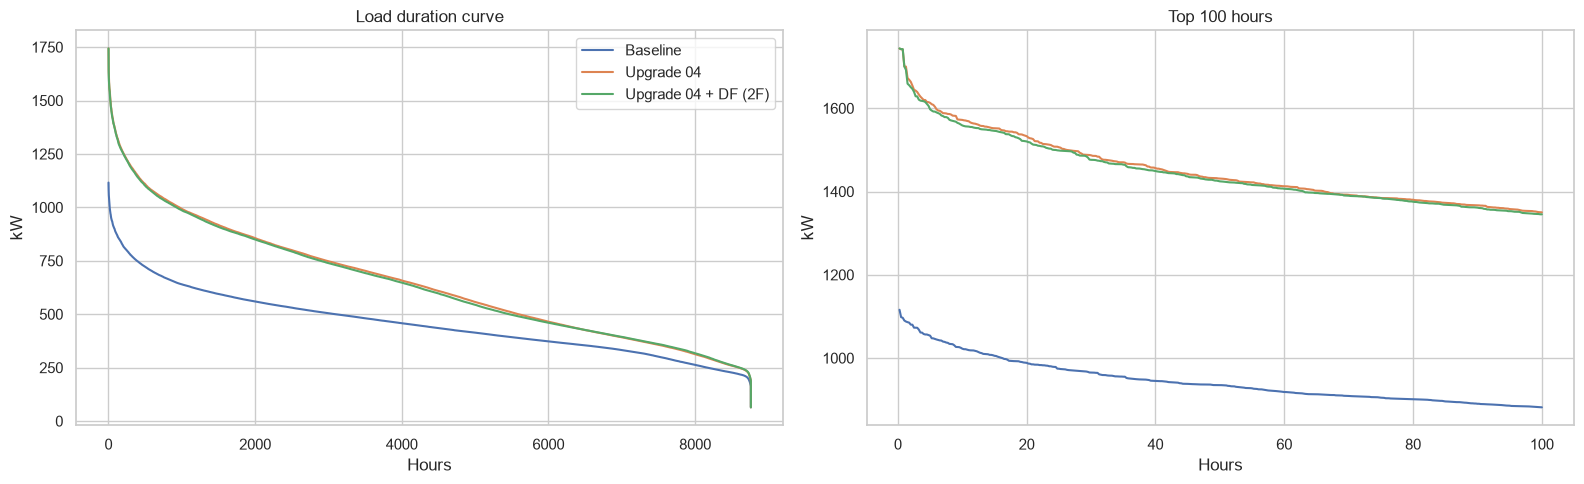

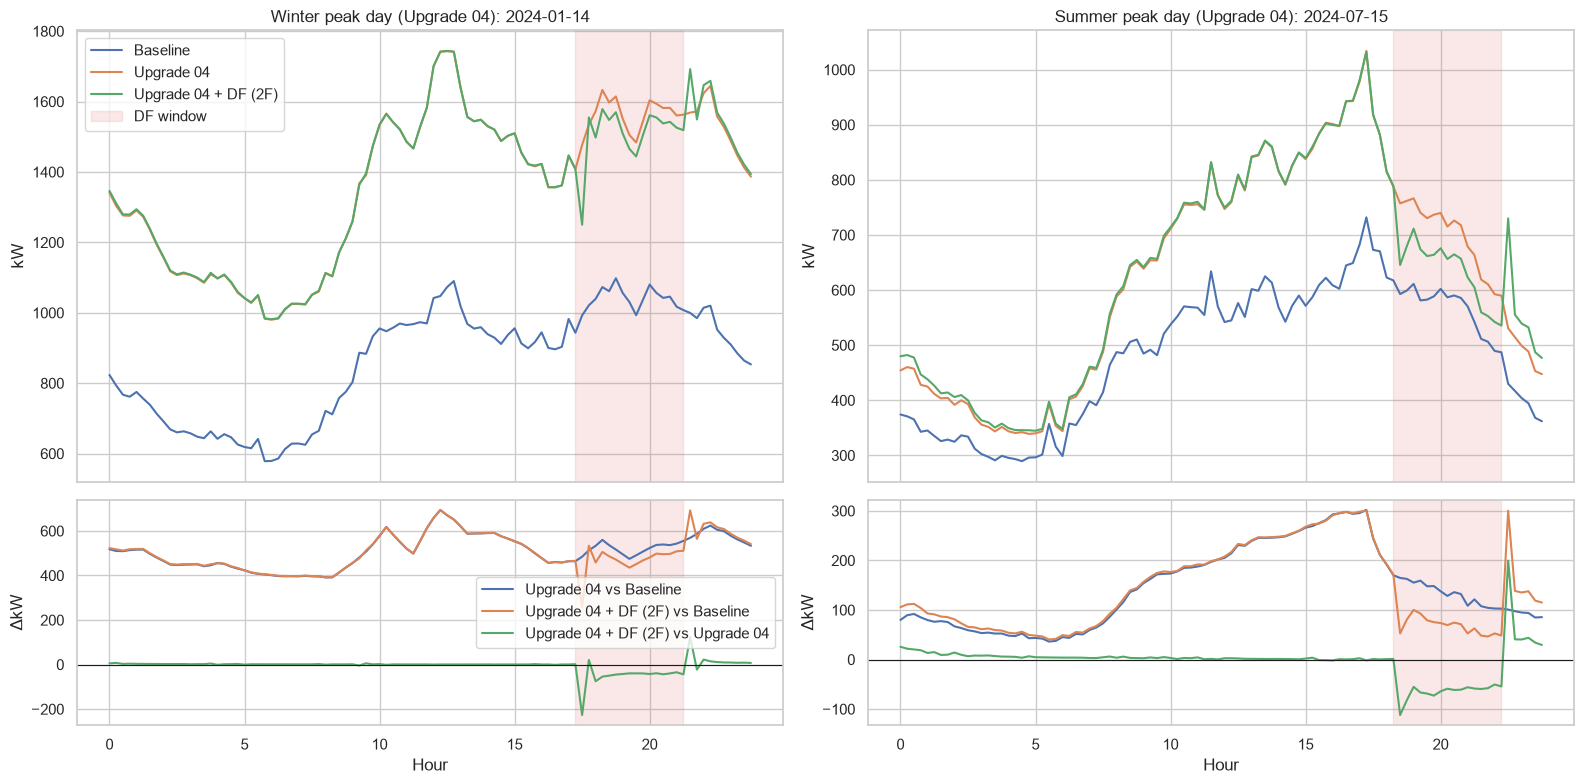

Daily peak (kW)  Peak hour  \
Season Date       Scenario                                           
Winter 2024-01-14 Baseline                     1,098.22      18.75   
                  Upgrade 04                   1,743.42      12.50   
                  Upgrade 04 + DF (2F)         1,743.78      12.50   
Summer 2024-07-15 Baseline                       732.08      17.25   
                  Upgrade 04                   1,034.00      17.25   
                  Upgrade 04 + DF (2F)         1,032.31      17.25   

                                        DF-window peak (kW)  \
Season Date       Scenario                                    
Winter 2024-01-14 Baseline                         1,098.22   
                  Upgrade 04                       1,633.04   
                  Upgrade 04 + DF (2F)             1,578.78   
Summer 2024-07-15 Baseline                           611.27   
                  Upgrade 04                         766.46   
                  Upgrade 04 + DF (2F)               711.45   

                                        DF-window peak hour  \
Season Date       Scenario                                    
Winter 2024-01-14 Baseline                            18.75   
                  Upgrade 04                          18.25   
                  Upgrade 04 + DF (2F)                18.25   
Summer 2024-07-15 Baseline                            19.00   
                  Upgrade 04                          19.00   
                  Upgrade 04 + DF (2F)                19.00   

                                        Daily energy (MWh)  \
Season Date       Scenario                                   
Winter 2024-01-14 Baseline                           20.70   
                  Upgrade 04                         32.91   
                  Upgrade 04 + DF (2F)               32.77   
Summer 2024-07-15 Baseline                           11.63   
                  Upgrade 04                         15.09   
                  Upgrade 04 + DF (2F)               15.01   

                                        DF-window energy (MWh)  
Season Date       Scenario                                      
Winter 2024-01-14 Baseline                                4.16  
                  Upgrade 04                              6.25  
                  Upgrade 04 + DF (2F)                    6.04  
Summer 2024-07-15 Baseline                                2.26  
                  Upgrade 04                              2.79  
                  Upgrade 04 + DF (2F)                    2.53

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for c in scen:
    s = np.sort(sys_kw[c].values)[::-1]
    hrs = np.arange(1, len(s) + 1) * dt_h
    axes[0].plot(hrs, s, label=c)
    axes[1].plot(hrs[: int(100 / dt_h)], s[: int(100 / dt_h)], label=c)
axes[0].set(title="Load duration curve", xlabel="Hours", ylabel="kW")
axes[1].set(title="Top 100 hours", xlabel="Hours", ylabel="kW")
axes[0].legend(); plt.tight_layout(); fig.savefig(FIG_DIR / "load_duration.png", dpi=150); plt.show()

# Winter and summer peak days (from PEAK_DAY_SCEN's seasonal peaks); DF window shaded
peak_days = {sea: sys_kw.loc[sys_kw["season"] == sea, PEAK_DAY_SCEN].idxmax().normalize() for sea in ["Winter", "Summer"]}
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
day_rows = []
for j, (sea, d) in enumerate(peak_days.items()):
    day = sys_kw.loc[d: d + pd.Timedelta("1D") - pd.Timedelta("1s")]
    win = day["in_window"].to_numpy()
    day = day[scen]
    day.index = day.index.hour + day.index.minute / 60
    lo, hi = day.index[win].min() - dt_h, day.index[win].max()  # interval-end labels -> interval span
    day.plot(ax=axes[0, j], legend=j == 0)
    axes[0, j].set(title=f"{sea} peak day ({PEAK_DAY_SCEN}): {d.date()}", ylabel="kW")
    pd.DataFrame({cmp_label(a, b): day[a] - day[b] for a, b in COMPARISONS}).plot(ax=axes[1, j], legend=j == 0)
    axes[1, j].axhline(0, color="k", lw=0.8)
    axes[1, j].set(xlabel="Hour", ylabel="ΔkW")
    for ax in axes[:, j]:
        ax.axvspan(lo, hi, color="tab:red", alpha=0.1, label="DF window" if ax is axes[0, 0] else None)
    for c in scen:
        day_rows.append({"Season": sea, "Date": d.date(), "Scenario": c, "Daily peak (kW)": day[c].max(),
                         "Peak hour": day[c].idxmax(), "DF-window peak (kW)": day[c][win].max(),
                         "DF-window peak hour": day[c][win].idxmax(), "Daily energy (MWh)": day[c].sum() * dt_h / 1000,
                         "DF-window energy (MWh)": day[c][win].sum() * dt_h / 1000})
axes[0, 0].legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "peak_day_profiles_winter_summer.png", dpi=150); plt.show()

peak_day_tbl = pd.DataFrame(day_rows).set_index(["Season", "Date", "Scenario"])
peak_day_tbl.to_csv(FIG_DIR / "peak_day_summary.csv")
peak_day_tbl

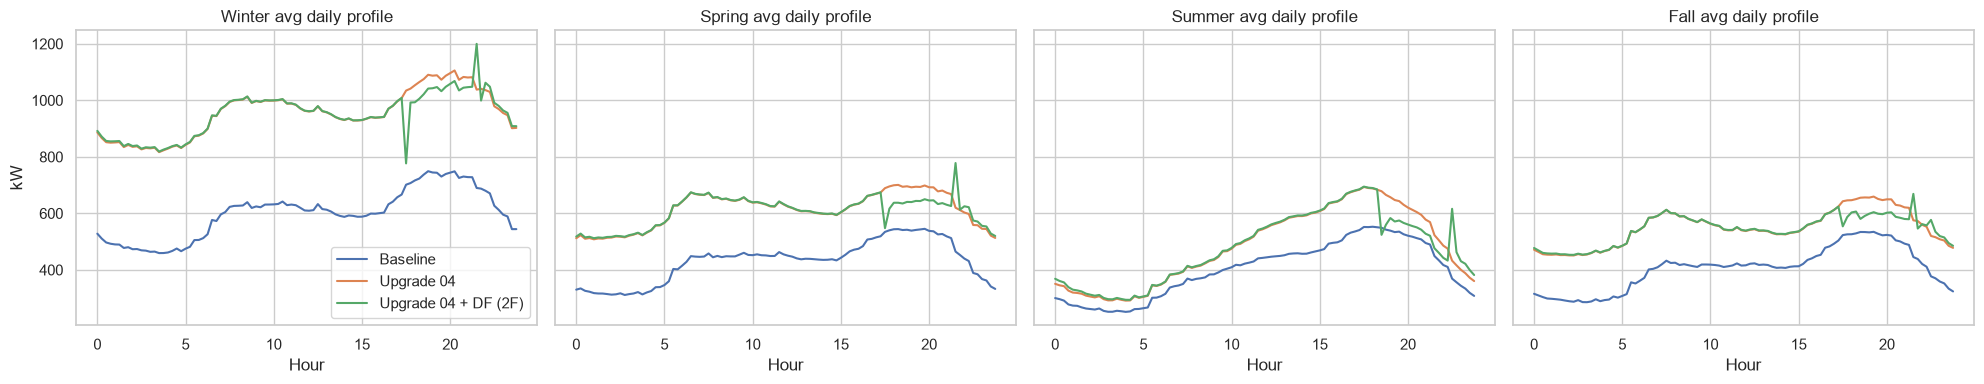

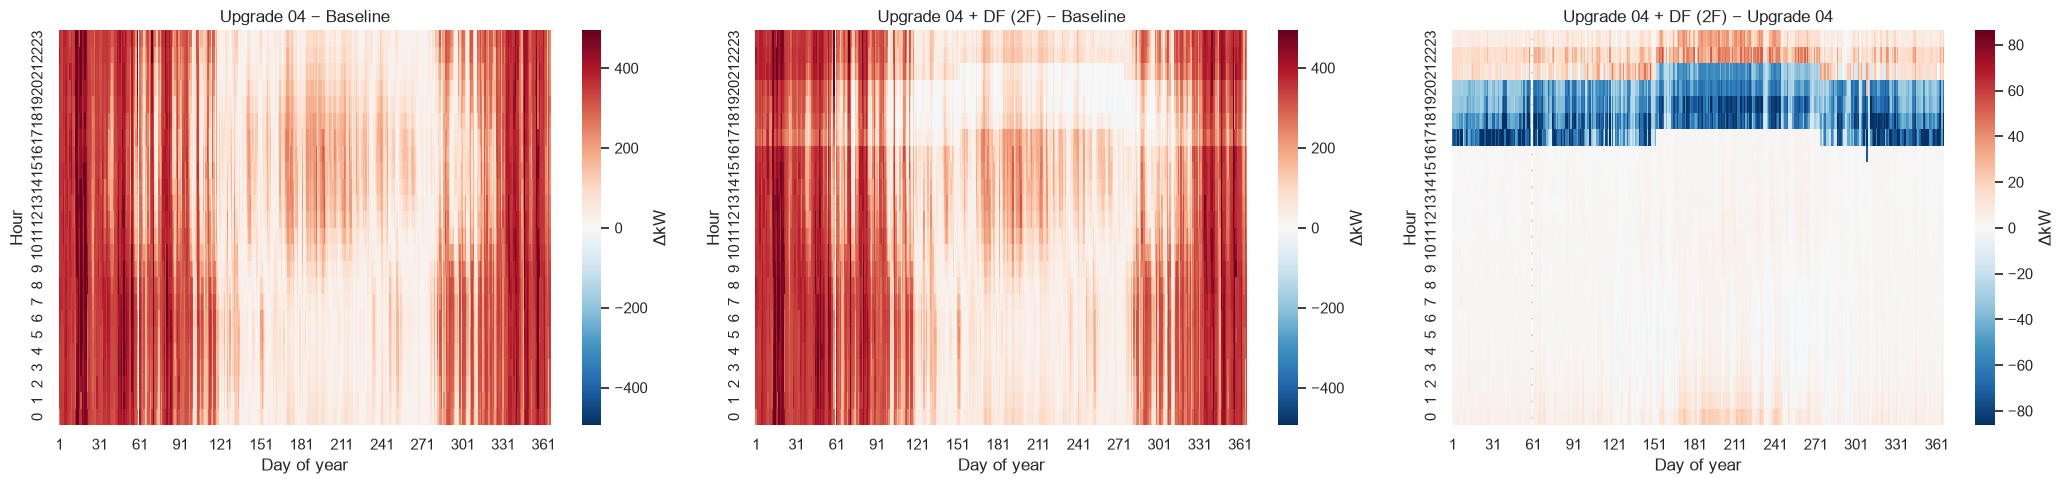

In [22]:
# Average daily profile by season
fig, axes = plt.subplots(1, 4, figsize=(20, 4), sharey=True)
hod = sys_kw.index.hour + sys_kw.index.minute / 60
for ax, sea in zip(axes, SEASON_ORDER):
    m = sys_kw["season"] == sea
    sys_kw.loc[m, scen].groupby(hod[m]).mean().plot(ax=ax, legend=sea == "Winter")
    ax.set(title=f"{sea} avg daily profile", xlabel="Hour", ylabel="kW")
plt.tight_layout(); fig.savefig(FIG_DIR / "seasonal_avg_profiles.png", dpi=150); plt.show()

# Heatmaps of pairwise change (day x hour)
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(7 * len(COMPARISONS), 5))
for ax, (c, b) in zip(np.atleast_1d(axes), COMPARISONS):
    d = (sys_kw[c] - sys_kw[b]).resample("1h").mean()
    hm = d.groupby([d.index.hour, d.index.dayofyear]).mean().unstack()
    v = np.nanpercentile(np.abs(hm.values), 99)
    sns.heatmap(hm, ax=ax, cmap="RdBu_r", center=0, vmin=-v, vmax=v, cbar_kws={"label": "ΔkW"}, xticklabels=30)
    ax.set(title=f"{c} − {b}", xlabel="Day of year", ylabel="Hour"); ax.invert_yaxis()
plt.tight_layout(); fig.savefig(FIG_DIR / "delta_heatmaps.png", dpi=150); plt.show()

## Node-level (transformer) analysis

In [23]:
win_mask = sys_kw["in_window"].to_numpy()
node = {}
for c, df in data.items():
    node[(c, "energy_MWh")] = df.sum() * dt_h / 1000
    node[(c, "peak_kW")] = df.max()
    node[(c, "peak_window_kW")] = df[win_mask].max()
    for sea in SEASON_ORDER:
        node[(c, f"peak_{sea}_kW")] = df[df.index.month.map(SEASONS) == sea].max()
node = pd.DataFrame(node)
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    node[(lab, "energy_Δ%")] = 100 * (node[(a, "energy_MWh")] / node[(b, "energy_MWh")] - 1)
    node[(lab, "peak_ΔkW")] = node[(a, "peak_kW")] - node[(b, "peak_kW")]
    node[(lab, "peak_Δ%")] = 100 * (node[(a, "peak_kW")] / node[(b, "peak_kW")] - 1)
    node[(lab, "peak_window_ΔkW")] = node[(a, "peak_window_kW")] - node[(b, "peak_window_kW")]
    node[(lab, "peak_window_Δ%")] = 100 * (node[(a, "peak_window_kW")] / node[(b, "peak_window_kW")] - 1)
node = node.replace([np.inf, -np.inf], np.nan)
node.to_csv(FIG_DIR / "node_summary.csv")

# Descriptive statistics across nodes
display(node.xs("peak_kW", axis=1, level=1).describe().T.join(
    node.xs("energy_MWh", axis=1, level=1).describe().T, lsuffix=" peak_kW", rsuffix=" energy_MWh"))

# Pairwise node changes: stats and count of nodes with peak up/down (all hours vs DF window)
pair_stats = {}
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    for per, k in [("All hours", "peak"), ("DF window", "peak_window")]:
        dk = node[(lab, f"{k}_ΔkW")]
        pair_stats[(lab, per)] = {
            "mean peak ΔkW": dk.mean(),
            "median peak Δ%": node[(lab, f"{k}_Δ%")].median(),
            "median energy Δ%": node[(lab, "energy_Δ%")].median(),
            "# nodes peak ↑ (>0.1 kW)": (dk > 0.1).sum(),
            "# nodes peak ↓ (<-0.1 kW)": (dk < -0.1).sum(),
        }
pair_stats = pd.DataFrame(pair_stats).T
pair_stats.to_csv(FIG_DIR / "node_pairwise_stats.csv")
pair_stats

,count peak_kW,mean peak_kW,std peak_kW,min peak_kW,25% peak_kW,50% peak_kW,75% peak_kW,max peak_kW,count energy_MWh,mean energy_MWh,std energy_MWh,min energy_MWh,25% energy_MWh,50% energy_MWh,75% energy_MWh,max energy_MWh
Baseline,146.00,14.83,9.99,0.00,8.49,11.79,18.88,53.21,146.00,27.49,25.15,0.00,10.05,17.22,37.48,117.62
Upgrade 04,146.00,18.31,12.72,0.00,10.02,13.56,23.07,69.36,146.00,38.89,34.77,0.00,16.24,24.81,50.31,164.04
Upgrade 04 + DF (2F),146.00,18.30,12.71,0.00,9.87,13.52,23.13,69.36,146.00,38.56,34.46,0.00,16.02,24.61,49.73,162.26


mean peak ΔkW  median peak Δ%  \
Upgrade 04 vs Baseline             All hours           3.48           13.86   
                                   DF window           3.10           13.03   
Upgrade 04 + DF (2F) vs Baseline   All hours           3.46           13.10   
                                   DF window           2.79           10.84   
Upgrade 04 + DF (2F) vs Upgrade 04 All hours          -0.02            0.00   
                                   DF window          -0.31           -0.53   

                                              median energy Δ%  \
Upgrade 04 vs Baseline             All hours             43.18   
                                   DF window             43.18   
Upgrade 04 + DF (2F) vs Baseline   All hours             42.03   
                                   DF window             42.03   
Upgrade 04 + DF (2F) vs Upgrade 04 All hours             -0.87   
                                   DF window             -0.87   

                                              # nodes peak ↑ (>0.1 kW)  \
Upgrade 04 vs Baseline             All hours                    106.00   
                                   DF window                    106.00   
Upgrade 04 + DF (2F) vs Baseline   All hours                    106.00   
                                   DF window                    106.00   
Upgrade 04 + DF (2F) vs Upgrade 04 All hours                     15.00   
                                   DF window                      5.00   

                                              # nodes peak ↓ (<-0.1 kW)  
Upgrade 04 vs Baseline             All hours                       2.00  
                                   DF window                       1.00  
Upgrade 04 + DF (2F) vs Baseline   All hours                       2.00  
                                   DF window                       5.00  
Upgrade 04 + DF (2F) vs Upgrade 04 All hours                      24.00  
                                   DF window                      71.00

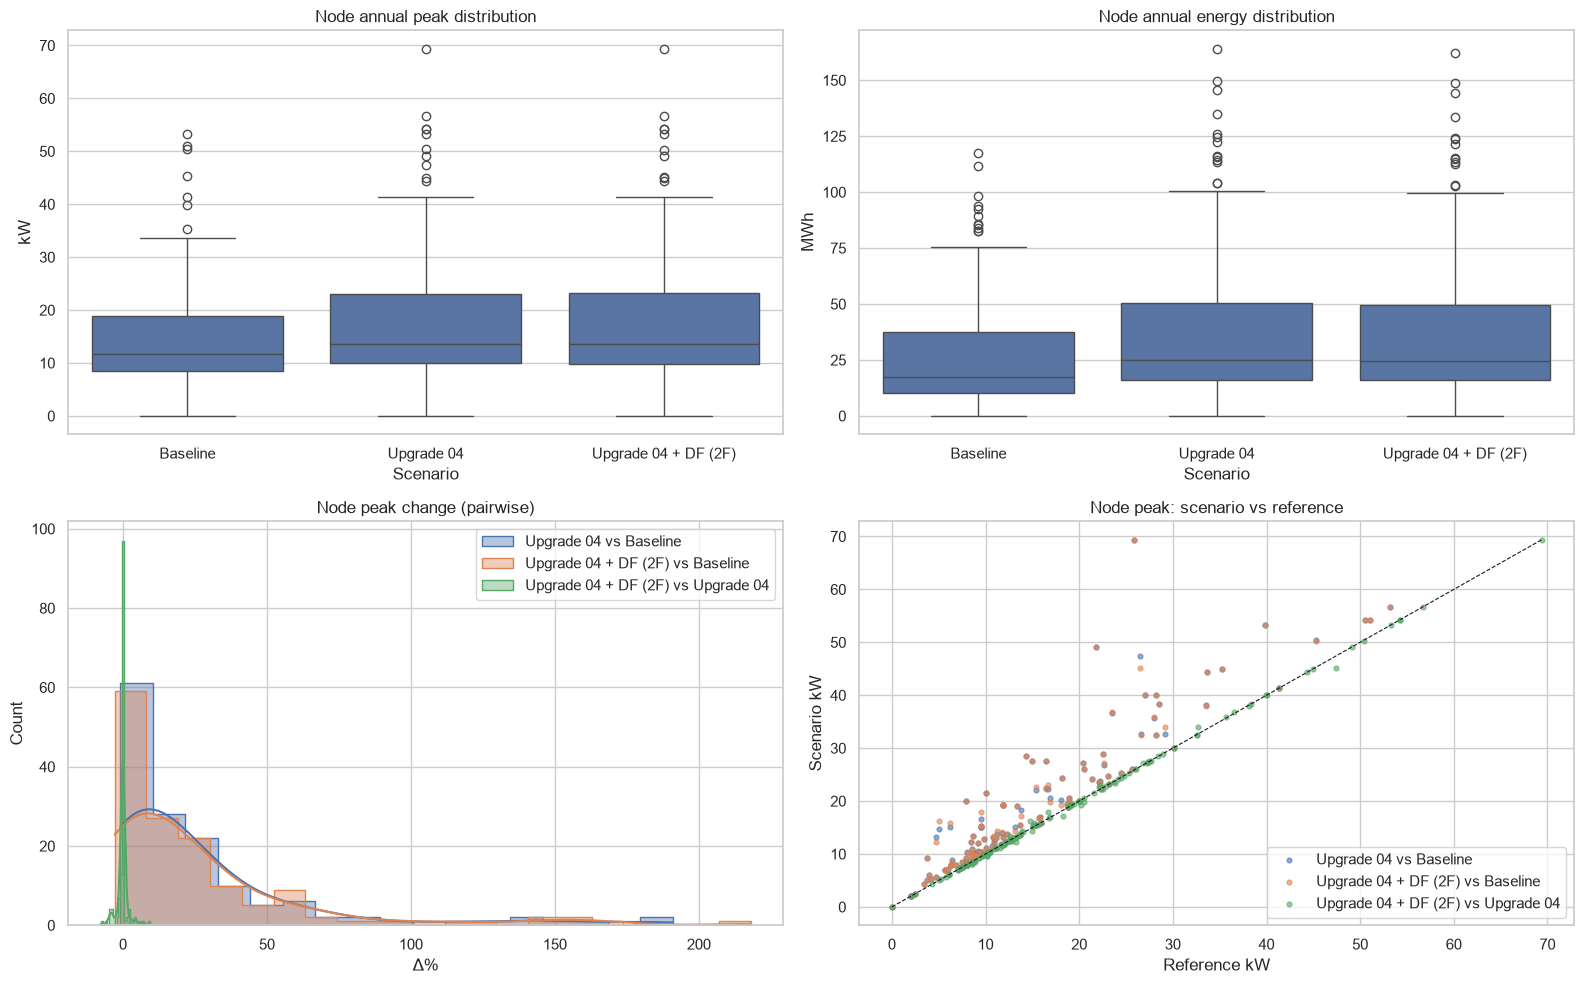

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
pk_long = node.xs("peak_kW", axis=1, level=1).melt(var_name="Scenario", value_name="kW")
en_long = node.xs("energy_MWh", axis=1, level=1).melt(var_name="Scenario", value_name="MWh")
sns.boxplot(data=pk_long, x="Scenario", y="kW", ax=axes[0, 0]); axes[0, 0].set_title("Node annual peak distribution")
sns.boxplot(data=en_long, x="Scenario", y="MWh", ax=axes[0, 1]); axes[0, 1].set_title("Node annual energy distribution")
for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    sns.histplot(node[(lab, "peak_Δ%")].dropna(), ax=axes[1, 0], label=lab, kde=True, element="step", alpha=0.4)
    axes[1, 1].scatter(node[(b, "peak_kW")], node[(a, "peak_kW")], s=12, alpha=0.6, label=lab)
axes[1, 0].set(title="Node peak change (pairwise)", xlabel="Δ%"); axes[1, 0].legend()
lim = node.xs("peak_kW", axis=1, level=1).max().max()
axes[1, 1].plot([0, lim], [0, lim], "k--", lw=0.8)
axes[1, 1].set(title="Node peak: scenario vs reference", xlabel="Reference kW", ylabel="Scenario kW"); axes[1, 1].legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "node_distributions.png", dpi=150); plt.show()

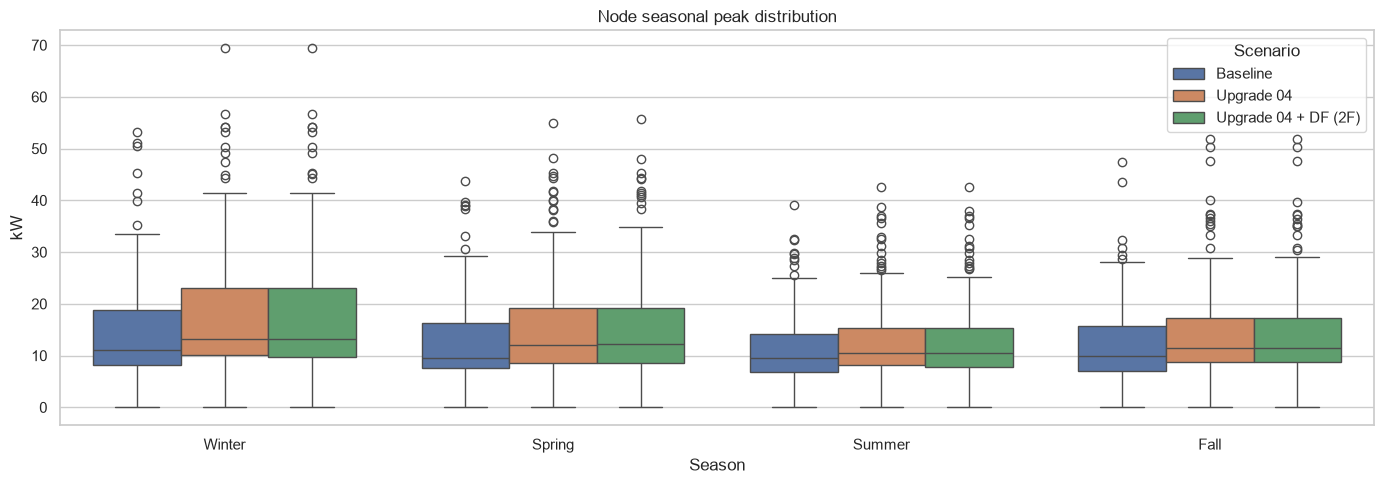

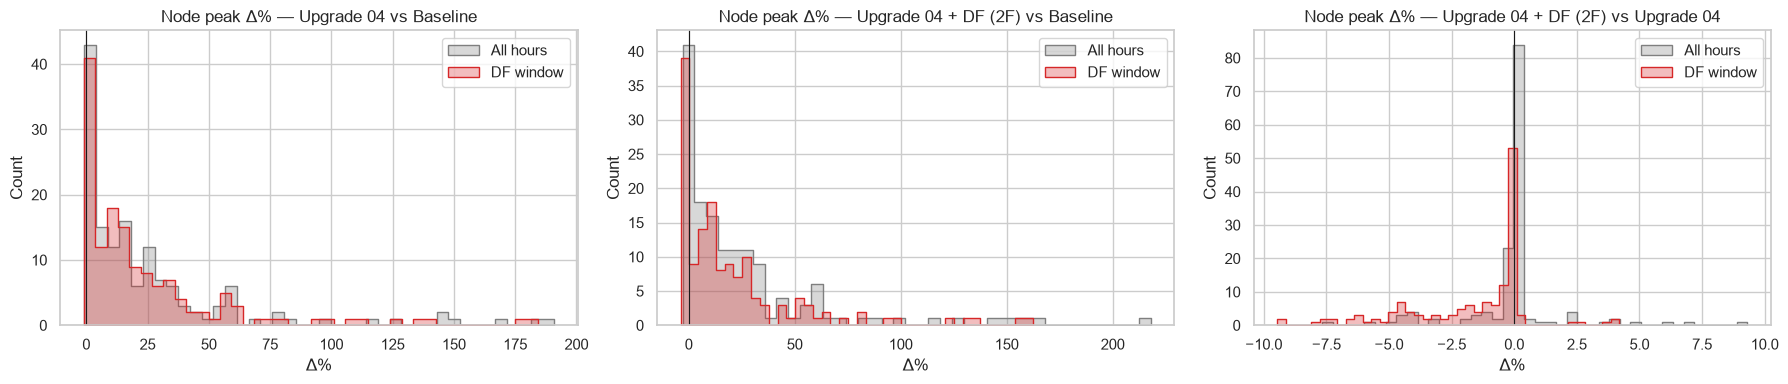

,All hours,DF window
Coincidence factor,,
Baseline,0.52,0.55
Upgrade 04,0.65,0.68
Upgrade 04 + DF (2F),0.65,0.68


Top 10 nodes by peak increase — Upgrade 04 vs Baseline


Baseline Upgrade 04 Upgrade 04 vs Baseline        
               peak_kW    peak_kW               peak_ΔkW peak_Δ%
220270653_RES    25.86      69.36                  43.50  168.22
220270497_RES    21.80      49.12                  27.32  125.31
220270566_RES    26.51      47.46                  20.95   79.03
220270519_RES    14.30      28.43                  14.13   98.84
220270568_RES    39.88      53.25                  13.37   33.53
220270617_RES    23.53      36.58                  13.04   55.44
220270660_RES    27.04      40.03                  12.98   48.01
220270506_RES    15.01      27.56                  12.56   83.69
220270550_RES     7.97      19.98                  12.01  150.78
310064740_RES    28.17      39.96                  11.79   41.86

Top 10 nodes by peak increase — Upgrade 04 + DF (2F) vs Baseline


Baseline Upgrade 04 + DF (2F) Upgrade 04 + DF (2F) vs Baseline  \
               peak_kW              peak_kW                         peak_ΔkW   
220270653_RES    25.86                69.36                            43.50   
220270497_RES    21.80                49.12                            27.32   
220270566_RES    26.51                45.19                            18.68   
220270519_RES    14.30                28.44                            14.14   
220270568_RES    39.88                53.26                            13.38   
220270617_RES    23.53                36.82                            13.29   
220270660_RES    27.04                40.05                            13.01   
220270506_RES    15.01                27.59                            12.58   
220270550_RES     7.97                19.98                            12.01   
310064740_RES    28.17                39.99                            11.82   

                       
              peak_Δ%  
220270653_RES  168.22  
220270497_RES  125.31  
220270566_RES   70.47  
220270519_RES   98.92  
220270568_RES   33.54  
220270617_RES   56.46  
220270660_RES   48.09  
220270506_RES   83.86  
220270550_RES  150.78  
310064740_RES   41.94

Top 10 nodes by peak increase — Upgrade 04 + DF (2F) vs Upgrade 04


Upgrade 04 Upgrade 04 + DF (2F)  \
                 peak_kW              peak_kW   
220269819_RES      14.79                16.16   
220270560_RES      32.66                34.00   
220269966_RES      16.66                17.85   
220534982_RES      22.25                23.13   
220270561_RES      12.63                13.41   
220270692_RES      15.19                15.95   
220270495_RES      22.06                22.58   
220270498_RES      13.86                14.37   
220270563_RES      15.02                15.36   
220270564_RES      15.02                15.36   

              Upgrade 04 + DF (2F) vs Upgrade 04          
                                        peak_ΔkW peak_Δ%  
220269819_RES                               1.38    9.31  
220270560_RES                               1.33    4.08  
220269966_RES                               1.18    7.11  
220534982_RES                               0.88    3.94  
220270561_RES                               0.77    6.11  
220270692_RES                               0.76    4.99  
220270495_RES                               0.52    2.34  
220270498_RES                               0.51    3.70  
220270563_RES                               0.33    2.21  
220270564_RES                               0.33    2.21

Top 10 nodes by DF-window peak reduction — Upgrade 04 + DF (2F) vs Upgrade 04


Upgrade 04 Upgrade 04 + DF (2F)  \
              peak_window_kW       peak_window_kW   
220270497_RES          41.94                39.14   
220270653_RES          58.12                55.55   
220270566_RES          47.46                45.19   
310007575_RES          37.74                35.84   
220501626_RES          23.40                21.52   
220270506_RES          21.56                19.96   
220270519_RES          23.80                22.28   
220270550_RES          18.94                17.56   
220270695_RES          18.91                17.71   
220534968_RES          17.76                16.62   

              Upgrade 04 + DF (2F) vs Upgrade 04                 
                                 peak_window_ΔkW peak_window_Δ%  
220270497_RES                              -2.79          -6.66  
220270653_RES                              -2.57          -4.42  
220270566_RES                              -2.27          -4.78  
310007575_RES                              -1.91          -5.05  
220501626_RES                              -1.88          -8.03  
220270506_RES                              -1.60          -7.44  
220270519_RES                              -1.52          -6.39  
220270550_RES                              -1.38          -7.26  
220270695_RES                              -1.19          -6.31  
220534968_RES                              -1.13          -6.38

In [25]:
# Seasonal node peak distributions & top nodes by peak increase
sea_long = pd.concat([
    node.xs(f"peak_{s}_kW", axis=1, level=1).melt(var_name="Scenario", value_name="kW").assign(Season=s)
    for s in SEASON_ORDER])
plt.figure(figsize=(14, 5))
sns.boxplot(data=sea_long, x="Season", y="kW", hue="Scenario")
plt.title("Node seasonal peak distribution"); plt.tight_layout()
plt.savefig(FIG_DIR / "node_seasonal_peaks.png", dpi=150); plt.show()

# Node peak change: all hours vs DF window
fig, axes = plt.subplots(1, len(COMPARISONS), figsize=(6 * len(COMPARISONS), 4))
for ax, (a, b) in zip(axes, COMPARISONS):
    lab = cmp_label(a, b)
    for k, per, col in [("peak_Δ%", "All hours", "tab:gray"), ("peak_window_Δ%", "DF window", "tab:red")]:
        sns.histplot(node[(lab, k)].dropna(), ax=ax, label=per, color=col, element="step", alpha=0.3, bins=40)
    ax.axvline(0, color="k", lw=0.8); ax.set(title=f"Node peak Δ% — {lab}", xlabel="Δ%"); ax.legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "node_peak_change_window_vs_all.png", dpi=150); plt.show()

# Coincidence factor: system peak / sum of node peaks
cf = pd.DataFrame({
    "All hours": {c: sys_kw[c].max() / data[c].max().sum() for c in scen},
    "DF window": {c: sys_kw.loc[win_mask, c].max() / data[c][win_mask].max().sum() for c in scen},
})
display(cf.rename_axis("Coincidence factor"))

for a, b in COMPARISONS:
    lab = cmp_label(a, b)
    top = node[[(b, "peak_kW"), (a, "peak_kW"), (lab, "peak_ΔkW"), (lab, "peak_Δ%")]].sort_values((lab, "peak_ΔkW"))
    print(f"Top 10 nodes by peak increase — {lab}"); display(top.tail(10)[::-1])
    if (a, b) == (DF, UP):
        top_w = node[[(b, "peak_window_kW"), (a, "peak_window_kW"), (lab, "peak_window_ΔkW"), (lab, "peak_window_Δ%")]]
        print(f"Top 10 nodes by DF-window peak reduction — {lab}"); display(top_w.sort_values((lab, "peak_window_ΔkW")).head(10))